
# C00b — Soft Self-History Attenuation

## Motivation

C00 established that hard restriction of generated self-history can move the
completed-text context-utility signature toward the matched human distribution.
However, manual inspection of the strongest hard-cap condition (\(K=32\)) showed
clear repetition of ideas and loss of long-range continuity.

C00b asks a more precise mechanistic question:

\[
\boxed{
\text{Can we weaken the mathematical influence of old self-history}
}
\]

\[
\boxed{
\text{without deleting it, and still move the output trace toward humans?}
}
\]

The visible writing task, generator checkpoint, greedy decoding rule, and prompt
are fixed. Every generated token remains in the model's KV cache.

Only its **direct attention influence on later generated tokens** is modified.

---

## Intervention

Let \(P\) be the fixed prompt and \(x_1,\ldots,x_t\) the generated continuation.

Prompt tokens are never attenuated.

For a generated query token \(x_t\) attending to an earlier generated key \(x_j\),
define generated-token age

\[
d=t-j.
\]

The normal attention score is

\[
s_{t,j}=\frac{q_t^\top k_j}{\sqrt{d_h}}.
\]

C00b adds a distance-dependent bias

\[
b_\lambda(d)
=
-\lambda
\frac{\max(d-r,0)}{r},
\]

giving

\[
s'_{t,j}=s_{t,j}+b_\lambda(d).
\]

The recent window \(r\) receives no penalty.

Because attention probabilities are proportional to \(e^s\), the intervention
multiplies the attention odds of an old generated key by

\[
\exp\left[
-\lambda\frac{\max(d-r,0)}{r}
\right].
\]

Thus old information remains present and can still be used, but receives a
controlled recency prior.

### Frozen intervention grid

\[
r=64
\]

and

\[
\lambda\in\{0,\ 0.125,\ 0.25,\ 0.5,\ 1.0\}.
\]

`L000` is the same custom-mask code path with no attenuation and is the causal
baseline for all C00b contrasts.

At age 256 generated tokens, the direct attention-odds multipliers are roughly:

- \(\lambda=0.125:\ 0.687\)
- \(\lambda=0.25:\ 0.472\)
- \(\lambda=0.5:\ 0.223\)
- \(\lambda=1.0:\ 0.050\)

No old generated token is forcibly removed.

---

## Main causal question

For each attenuation strength \(\lambda\), compare the completed-text trace

\[
\mathbf U_\lambda
=
(U_{32},U_{128},U_{256})
\]

to both:

1. the unattenuated `L000` output;
2. the matched frozen human reference.

Define human-relative gap closure

\[
C_{\lambda,j}
=
1-
\frac{
E[U_{\lambda,j}-U_{H,j}]
}{
E[U_{0,j}-U_{H,j}]
}.
\]

A useful intervention should move \(U\) toward humans while preserving much more
of the document's content and organization than hard \(K=32\) truncation.

---

## Preservation diagnostics

C00b does **not** equate lexical repetition with quality.

Instead it reports several descriptive side effects:

- word count;
- repeated-4gram fraction;
- distinct-4;
- maximum repeated-4gram rate;
- sentence-level TF-IDF nearest-neighbor similarity (exploratory idea-redundancy proxy);
- EOS / max-token stopping behavior.

These are diagnostics only.

The notebook also ends with a manual pair browser so the actual prose can be
inspected before we decide how to formalize semantic/content preservation.


In [1]:

from pathlib import Path
import gc
import hashlib
import inspect
import json
import math
import re
import time
from collections import Counter

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
RESULTS = ROOT / "results"

C00_DIR = RESULTS / "causal" / "C00_effective_history_gap_closure"
OUT = RESULTS / "causal" / "C00b_soft_self_history_attenuation"
OUT.mkdir(parents=True, exist_ok=True)

GENERATOR_NAME = "Qwen2.5-1.5B-Instruct"
GENERATOR_CHECKPOINT = "Qwen/Qwen2.5-1.5B-Instruct"
SCORER_CHECKPOINT = "Qwen/Qwen3-0.6B-Base"

RECENT_WINDOW = 64

LAMBDA_BY_CONDITION = {
    "L000": 0.0,
    "L0125": 0.125,
    "L025": 0.25,
    "L050": 0.5,
    "L100": 1.0,
}
CONDITIONS = list(LAMBDA_BY_CONDITION)

MAX_NEW_TOKENS = 480

SCORER_PREFIX_LEN = 384
CONTEXTS = [8, 32, 128, 256]
N_TARGETS = 8
TARGET_POSITIONS = np.unique(
    np.linspace(
        max(CONTEXTS),
        SCORER_PREFIX_LEN - 1,
        N_TARGETS,
        dtype=int,
    )
)

N_BOOT = 10_000
BOOT_SEED = 20260902

# Set to a small integer only while debugging.
DEBUG_N = None

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float16 if DEVICE.type == "cuda" else torch.float32

if DEVICE.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True

print("ROOT:", ROOT)
print("C00_DIR:", C00_DIR)
print("OUT:", OUT)
print("device:", DEVICE)
print("recent unattenuated generated window:", RECENT_WINDOW)
print("conditions:", LAMBDA_BY_CONDITION)
print("target positions:", TARGET_POSITIONS)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT: ..
C00_DIR: ../results/causal/C00_effective_history_gap_closure
OUT: ../results/causal/C00b_soft_self_history_attenuation
device: cuda
recent unattenuated generated window: 64
conditions: {'L000': 0.0, 'L0125': 0.125, 'L025': 0.25, 'L050': 0.5, 'L100': 1.0}
target positions: [256 274 292 310 328 346 364 383]



## 1. Reuse the exact C00 frozen population

C00b does not choose new prompts after seeing C00.

It reuses:

- the exact frozen RAID prompts;
- the matched frozen human \(U\) references;
- the original C00 standard full-history generations and scores only as an
  external code-path audit.

The C00b confirmatory baseline itself is `L000`, generated through the same custom
attention-mask path as every attenuated condition.


In [2]:

required_paths = {
    "prompts": C00_DIR / "frozen_prompts.parquet",
    "human": C00_DIR / "frozen_human_reference.parquet",
    "c00_generations": C00_DIR / "generations.parquet",
    "c00_scores": C00_DIR / "context_scores.parquet",
}

missing = [str(p) for p in required_paths.values() if not p.exists()]
assert not missing, (
    "Missing required C00 artifacts. Run C00 first.\n"
    + "\n".join(missing)
)

prompts = pd.read_parquet(required_paths["prompts"]).copy()
human = pd.read_parquet(required_paths["human"]).copy()
c00_generations = pd.read_parquet(required_paths["c00_generations"]).copy()
c00_scores = pd.read_parquet(required_paths["c00_scores"]).copy()

prompts["source_id"] = prompts["source_id"].astype(str)
human["source_id"] = human["source_id"].astype(str)
c00_generations["source_id"] = c00_generations["source_id"].astype(str)
c00_scores["source_id"] = c00_scores["source_id"].astype(str)

if DEBUG_N is not None:
    keep_ids = set(prompts["source_id"].iloc[: int(DEBUG_N)])
    prompts = prompts[prompts["source_id"].isin(keep_ids)].copy()
    human = human[human["source_id"].isin(keep_ids)].copy()

SOURCE_IDS = prompts["source_id"].tolist()

assert prompts["source_id"].nunique() == len(prompts)
assert human["source_id"].nunique() >= len(SOURCE_IDS)

print("sources:", len(SOURCE_IDS))
display(prompts["domain"].value_counts().rename("n").to_frame())


sources: 60


,n
domain,
news,30
wiki,30



## 2. Soft-attention mechanism

Hugging Face attention accepts an additive four-dimensional mask of shape

\[
(B,1,Q,K).
\]

C00b uses cached incremental generation, so after prompt prefill each decoding
step has \(Q=1\).

For that one generated query:

- all prompt keys receive bias \(0\);
- the most recent 64 generated keys receive bias \(0\);
- older generated keys receive the finite negative bias \(b_\lambda(d)\).

The mask therefore changes attention logits before softmax while retaining every
old generated key/value in cache.


In [3]:

def normalize_eos_ids(tok, model):
    ids = []

    for obj in [
        tok,
        getattr(model, "generation_config", None),
        model.config,
    ]:
        if obj is None:
            continue

        x = getattr(obj, "eos_token_id", None)

        if x is None:
            continue

        if isinstance(x, (list, tuple, set)):
            ids.extend(int(v) for v in x if v is not None)
        else:
            ids.append(int(x))

    return sorted(set(ids))


def supports_logits_to_keep(model):
    try:
        return "logits_to_keep" in inspect.signature(model.forward).parameters
    except Exception:
        return False


def load_generator(checkpoint):
    tok = AutoTokenizer.from_pretrained(checkpoint, use_fast=True)

    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token

    kwargs = dict(low_cpu_mem_usage=True)

    # SDPA accepts additive 4D float masks and is much more memory-efficient
    # than eager attention on the user's 8 GB GPU.
    try:
        model = AutoModelForCausalLM.from_pretrained(
            checkpoint,
            dtype=DTYPE if DEVICE.type == "cuda" else torch.float32,
            attn_implementation="sdpa",
            **kwargs,
        )
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(
            checkpoint,
            torch_dtype=DTYPE if DEVICE.type == "cuda" else torch.float32,
            attn_implementation="sdpa",
            **kwargs,
        )

    model.to(DEVICE).eval()
    return tok, model


def build_prompt_ids(tok, prompt):
    messages = [{"role": "user", "content": str(prompt)}]

    encoded = tok.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
    )

    if isinstance(encoded, torch.Tensor):
        ids = encoded
    elif hasattr(encoded, "input_ids"):
        ids = encoded.input_ids
    else:
        ids = encoded["input_ids"]

    if ids.ndim == 1:
        ids = ids.unsqueeze(0)

    assert ids.ndim == 2 and ids.shape[0] == 1
    return ids.to(DEVICE)


def soft_history_step_mask(
    prompt_len,
    generated_index,
    lam,
    recent_window=RECENT_WINDOW,
    dtype=DTYPE,
    device=DEVICE,
):
    """
    Mask for one cached generated-token query.

    generated_index:
        0-based index of the query token among generated tokens.

    KV layout at this step:
        [prompt keys] + [generated keys 0..generated_index]

    Shape:
        (1, 1, 1, prompt_len + generated_index + 1)
    """

    assert generated_index >= 0
    assert lam >= 0
    assert recent_window >= 1

    n_generated_keys = generated_index + 1
    kv_len = prompt_len + n_generated_keys

    # Prompt is always fully visible.
    mask = torch.zeros(
        (1, 1, 1, kv_len),
        dtype=dtype,
        device=device,
    )

    # Ages of generated keys from oldest -> current/self:
    # generated_index, ..., 2, 1, 0
    ages = torch.arange(
        generated_index,
        -1,
        -1,
        dtype=torch.float32,
        device=device,
    )

    excess = torch.clamp(
        ages - float(recent_window),
        min=0.0,
    )

    bias = (
        -float(lam)
        * excess
        / float(recent_window)
    ).to(dtype)

    mask[..., prompt_len:] = bias
    return mask


@torch.inference_mode()
def generate_soft_history(
    tok,
    model,
    prompt,
    lam,
    recent_window=RECENT_WINDOW,
    max_new_tokens=MAX_NEW_TOKENS,
):
    """
    Greedy cached generation.

    Prompt prefill is standard/unmodified.
    Every generated token stays in KV cache.
    Only generated->older-generated attention receives a finite negative bias.
    """

    prompt_ids = build_prompt_ids(tok, prompt)
    prompt_len = int(prompt_ids.shape[1])

    eos_ids = set(normalize_eos_ids(tok, model))
    keep = supports_logits_to_keep(model)

    prefill_kwargs = {
        "input_ids": prompt_ids,
        "use_cache": True,
    }
    if keep:
        prefill_kwargs["logits_to_keep"] = 1

    out = model(**prefill_kwargs)

    cache = out.past_key_values
    next_id = int(out.logits[:, -1, :].argmax(dim=-1).item())

    generated = [next_id]

    del out

    if next_id in eos_ids or max_new_tokens == 1:
        return {
            "generated_text": tok.decode(
                generated,
                skip_special_tokens=True,
                clean_up_tokenization_spaces=False,
            ),
            "generated_token_ids_json": json.dumps(generated),
            "n_generator_tokens": len(generated),
            "ended_eos": bool(generated[-1] in eos_ids),
            "prompt_tokens": prompt_len,
        }

    # generated_index is the index of the token being fed as the query.
    # We already sampled generated[0] from prompt prefill.
    for generated_index in range(max_new_tokens - 1):

        current_id = generated[-1]

        input_ids = torch.tensor(
            [[current_id]],
            dtype=torch.long,
            device=DEVICE,
        )

        attn_mask = soft_history_step_mask(
            prompt_len=prompt_len,
            generated_index=generated_index,
            lam=lam,
            recent_window=recent_window,
            dtype=next(model.parameters()).dtype,
            device=DEVICE,
        )

        kwargs = {
            "input_ids": input_ids,
            "attention_mask": attn_mask,
            "past_key_values": cache,
            "use_cache": True,
        }
        if keep:
            kwargs["logits_to_keep"] = 1

        out = model(**kwargs)
        cache = out.past_key_values

        next_id = int(
            out.logits[:, -1, :].argmax(dim=-1).item()
        )

        generated.append(next_id)

        del input_ids, attn_mask, out

        if next_id in eos_ids:
            break

    return {
        "generated_text": tok.decode(
            generated,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False,
        ),
        "generated_token_ids_json": json.dumps(generated),
        "n_generator_tokens": len(generated),
        "ended_eos": bool(generated and generated[-1] in eos_ids),
        "prompt_tokens": prompt_len,
    }



## 3. Mechanism audit and code-path preflight

Three checks run before the expensive sweep.

### A. Designed attenuation

Print the exact attention-odds multipliers at representative generated-token ages.

### B. `L000` mask equivalence

At a fixed real C00 prefix, compare next-token logits under:

- ordinary no-cache causal attention;
- the custom 4D mask with \(\lambda=0\).

The greedy argmax must agree and the numerical difference should be tiny.

### C. Nonzero intervention

At the same prefix, \(\lambda=1\) must measurably change the next-token logits.

This is an implementation check only, not a scientific result.


In [4]:

print("Attention-odds multipliers relative to unattenuated attention:\n")

ages = [64, 128, 256, 384]

for condition, lam in LAMBDA_BY_CONDITION.items():
    vals = {}

    for age in ages:
        excess = max(age - RECENT_WINDOW, 0)
        multiplier = math.exp(
            -lam * excess / RECENT_WINDOW
        )
        vals[age] = multiplier

    print(condition, f"lambda={lam}:", vals)


Attention-odds multipliers relative to unattenuated attention:

L000 lambda=0.0: {64: 1.0, 128: 1.0, 256: 1.0, 384: 1.0}
L0125 lambda=0.125: {64: 1.0, 128: 0.8824969025845955, 256: 0.6872892787909722, 384: 0.5352614285189903}
L025 lambda=0.25: {64: 1.0, 128: 0.7788007830714049, 256: 0.4723665527410147, 384: 0.2865047968601901}
L050 lambda=0.5: {64: 1.0, 128: 0.6065306597126334, 256: 0.22313016014842982, 384: 0.0820849986238988}
L100 lambda=1.0: {64: 1.0, 128: 0.36787944117144233, 256: 0.049787068367863944, 384: 0.006737946999085467}


In [5]:

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

gen_tok, gen_model = load_generator(GENERATOR_CHECKPOINT)

# Use one real C00 prompt and a real standard-full prefix.
test_source = SOURCE_IDS[0]

test_prompt = prompts.loc[
    prompts["source_id"].eq(test_source),
    "prompt",
].iloc[0]

c00_full_text = c00_generations.loc[
    c00_generations["source_id"].eq(test_source)
    & c00_generations["condition"].eq("full"),
    "generated_text",
].iloc[0]

prompt_ids = build_prompt_ids(gen_tok, test_prompt)

# Take 160 generated tokens so old-history attenuation is actually active.
prefix_generated = gen_tok(
    str(c00_full_text),
    add_special_tokens=False,
)["input_ids"][:160]

assert len(prefix_generated) > RECENT_WINDOW

full_ids = torch.tensor(
    [prompt_ids[0].detach().cpu().tolist() + prefix_generated],
    dtype=torch.long,
    device=DEVICE,
)

keep = supports_logits_to_keep(gen_model)

base_kwargs = {
    "input_ids": full_ids,
    "use_cache": False,
}
if keep:
    base_kwargs["logits_to_keep"] = 1

with torch.inference_mode():
    base_out = gen_model(**base_kwargs)

base_logits = base_out.logits[:, -1, :].float()

# Construct a full 4D causal mask for the same sequence, with the same
# generated-history bias rule applied to every generated query row.
def full_soft_history_mask(
    prompt_len,
    n_generated,
    lam,
    recent_window=RECENT_WINDOW,
    dtype=DTYPE,
    device=DEVICE,
):
    L = prompt_len + n_generated

    q = torch.arange(L, device=device)[:, None]
    k = torch.arange(L, device=device)[None, :]

    causal = k <= q

    mask = torch.full(
        (L, L),
        float("-inf"),
        dtype=torch.float32,
        device=device,
    )
    mask[causal] = 0.0

    generated_q = q >= prompt_len
    generated_k = k >= prompt_len

    age = q - k

    excess = torch.clamp(
        age.float() - float(recent_window),
        min=0.0,
    )

    bias = -float(lam) * excess / float(recent_window)

    apply = causal & generated_q & generated_k

    mask = torch.where(
        apply,
        mask + bias,
        mask,
    )

    return mask[None, None, :, :].to(dtype)


mask0 = full_soft_history_mask(
    prompt_len=prompt_ids.shape[1],
    n_generated=len(prefix_generated),
    lam=0.0,
    dtype=next(gen_model.parameters()).dtype,
)

with torch.inference_mode():
    out0 = gen_model(
        input_ids=full_ids,
        attention_mask=mask0,
        use_cache=False,
        **({"logits_to_keep": 1} if keep else {}),
    )

logits0 = out0.logits[:, -1, :].float()

max_abs = float((base_logits - logits0).abs().max().item())
argmax_equal = bool(
    base_logits.argmax(dim=-1).item()
    == logits0.argmax(dim=-1).item()
)

print("L000 custom-mask equivalence:")
print("argmax equal:", argmax_equal)
print("max absolute logit difference:", max_abs)

assert argmax_equal, (
    "L000 custom mask changes greedy next-token choice. "
    "Do not run the experiment until this is understood."
)

mask1 = full_soft_history_mask(
    prompt_len=prompt_ids.shape[1],
    n_generated=len(prefix_generated),
    lam=1.0,
    dtype=next(gen_model.parameters()).dtype,
)

with torch.inference_mode():
    out1 = gen_model(
        input_ids=full_ids,
        attention_mask=mask1,
        use_cache=False,
        **({"logits_to_keep": 1} if keep else {}),
    )

logits1 = out1.logits[:, -1, :].float()

intervention_delta = float(
    (logits1 - logits0).abs().mean().item()
)

print("\nL100 intervention check:")
print("mean absolute next-token logit change:", intervention_delta)

assert intervention_delta > 1e-5

del (
    prompt_ids,
    full_ids,
    base_out,
    out0,
    out1,
    base_logits,
    logits0,
    logits1,
    mask0,
    mask1,
)

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\nPASS: soft-attention mechanism preflight.")


Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████| 338/338 [00:00<00:00, 847.32it/s]


L000 custom-mask equivalence:
argmax equal: True
max absolute logit difference: 0.0390625

L100 intervention check:
mean absolute next-token logit change: 0.2314383089542389

PASS: soft-attention mechanism preflight.



## 4. Generate the soft-attention sweep

All five conditions use the same cached custom-mask implementation.

The output file checkpoints after every source-condition generation and resumes
automatically.

Because the intervention keeps the full KV cache, this should be substantially
faster than recomputing the full sequence with `use_cache=False`.


In [6]:

GEN_PATH = OUT / "generations.parquet"

if GEN_PATH.exists():
    old = pd.read_parquet(GEN_PATH)
    rows = old.to_dict("records")
    done = set(
        zip(
            old["source_id"].astype(str),
            old["condition"].astype(str),
        )
    )
else:
    rows = []
    done = set()

total_needed = len(prompts) * len(CONDITIONS)

print(
    f"resume: {len(done)}/{total_needed} "
    "source-condition generations complete"
)

for _, p in tqdm(
    prompts.iterrows(),
    total=len(prompts),
    desc="C00b soft history",
):
    sid = str(p["source_id"])
    prompt = str(p["prompt"])

    for condition in CONDITIONS:

        key = (sid, condition)

        if key in done:
            continue

        lam = LAMBDA_BY_CONDITION[condition]

        t0 = time.time()

        result = generate_soft_history(
            gen_tok,
            gen_model,
            prompt,
            lam=lam,
            recent_window=RECENT_WINDOW,
            max_new_tokens=MAX_NEW_TOKENS,
        )

        rows.append({
            "source_id": sid,
            "domain": p["domain"],
            "title": p["title"],
            "generator": GENERATOR_NAME,
            "generator_checkpoint": GENERATOR_CHECKPOINT,
            "condition": condition,
            "lambda": lam,
            "recent_window": RECENT_WINDOW,
            "prompt_sha256": p["prompt_sha256"],
            "seconds": time.time() - t0,
            **result,
        })

        pd.DataFrame(rows).to_parquet(
            GEN_PATH,
            index=False,
        )

        done.add(key)

generations = pd.read_parquet(GEN_PATH)

assert len(generations) == total_needed
assert not generations.duplicated(
    ["source_id", "condition"]
).any()
assert set(generations["condition"]) == set(CONDITIONS)

print("saved:", GEN_PATH)
print("shape:", generations.shape)


resume: 0/300 source-condition generations complete


C00b soft history: 100%|████████████████████████████████████████████████████████████████████████████████| 60/60 [34:52<00:00, 34.87s/it]

saved: ../results/causal/C00b_soft_self_history_attenuation/generations.parquet
shape: (300, 15)



## 5. Generation audit and external `L000` comparison

First inspect whether soft attenuation changes stopping behavior.

Then compare `L000` to the original C00 standard full-history generation.

Exact text equality is ideal. Small divergence would indicate a numerical/code-path
difference, which is why C00b uses `L000` rather than old C00 `full` as its causal
baseline.


In [7]:

audit = (
    generations.groupby("condition")
    .agg(
        n=("source_id", "size"),
        mean_tokens=("n_generator_tokens", "mean"),
        median_tokens=("n_generator_tokens", "median"),
        eos_fraction=("ended_eos", "mean"),
        hit_max_fraction=(
            "n_generator_tokens",
            lambda x: np.mean(
                np.asarray(x) >= MAX_NEW_TOKENS
            ),
        ),
        mean_seconds=("seconds", "mean"),
    )
    .reindex(CONDITIONS)
)

display(audit)

# External code-path comparison to C00 standard full generation.
old_full = (
    c00_generations[
        c00_generations["condition"].eq("full")
        & c00_generations["source_id"].isin(set(SOURCE_IDS))
    ][["source_id", "generated_text"]]
    .rename(columns={"generated_text": "old_full"})
)

soft0 = (
    generations[
        generations["condition"].eq("L000")
    ][["source_id", "generated_text"]]
    .rename(columns={"generated_text": "soft0"})
)

path_audit = soft0.merge(
    old_full,
    on="source_id",
    validate="one_to_one",
)

path_audit["exact_match"] = (
    path_audit["soft0"] == path_audit["old_full"]
)

print(
    "L000 exact match to original C00 full:",
    f"{path_audit['exact_match'].mean():.1%}",
)

path_audit.to_parquet(
    OUT / "l000_vs_c00_full_text_audit.parquet",
    index=False,
)


,n,mean_tokens,median_tokens,eos_fraction,hit_max_fraction,mean_seconds
condition,,,,,,
L000,60,350.783333,361.5,0.716667,0.283333,7.376380
L0125,60,340.816667,352.5,0.733333,0.283333,7.128985
L025,60,330.816667,334.5,0.800000,0.200000,6.918451
L050,60,321.350000,320.0,0.816667,0.183333,6.748237
L100,60,319.933333,320.0,0.816667,0.183333,6.672634


L000 exact match to original C00 full: 63.3%


In [8]:

# Release generator before loading the independent scorer.
del gen_model
del gen_tok
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()



## 6. Frozen RELIC context-utility scoring

Exactly the same frozen Qwen3-0.6B scorer geometry as C00:

- first exactly 384 scorer tokens;
- contexts \(8,32,128,256\);
- eight target positions;
- \(U(k)=L_8-L_k\);
- \(U_{\rm long}=(U_{128}+U_{256})/2\).

Eligibility is reported separately by attenuation strength because stopping remains
a treatment outcome.


In [9]:

def scorer_supports_logits_to_keep(model):
    try:
        return "logits_to_keep" in inspect.signature(model.forward).parameters
    except Exception:
        return False


def load_scorer(checkpoint):
    tok = AutoTokenizer.from_pretrained(
        checkpoint,
        use_fast=True,
    )

    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token

    try:
        model = AutoModelForCausalLM.from_pretrained(
            checkpoint,
            dtype=DTYPE if DEVICE.type == "cuda" else torch.float32,
            low_cpu_mem_usage=True,
        )
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(
            checkpoint,
            torch_dtype=DTYPE if DEVICE.type == "cuda" else torch.float32,
            low_cpu_mem_usage=True,
        )

    model.to(DEVICE).eval()
    return tok, model


def encode_prefix(tok, text):
    return tok(
        str(text),
        add_special_tokens=False,
        truncation=False,
    )["input_ids"][:SCORER_PREFIX_LEN]


@torch.inference_mode()
def score_context_utility(model, ids):
    assert len(ids) == SCORER_PREFIX_LEN

    keep = scorer_supports_logits_to_keep(model)
    losses = {k: [] for k in CONTEXTS}

    for k in CONTEXTS:

        seqs = []
        target_ids = []

        for t in TARGET_POSITIONS:
            seqs.append(
                torch.tensor(
                    ids[t-k:t],
                    dtype=torch.long,
                )
            )
            target_ids.append(int(ids[t]))

        batch = torch.stack(
            seqs,
            dim=0,
        ).to(DEVICE)

        targets = torch.tensor(
            target_ids,
            dtype=torch.long,
            device=DEVICE,
        )

        kwargs = {
            "input_ids": batch,
            "use_cache": False,
        }
        if keep:
            kwargs["logits_to_keep"] = 1

        out = model(**kwargs)

        logits = out.logits[:, -1, :].float()
        logp = torch.log_softmax(logits, dim=-1)

        nll = -logp.gather(
            1,
            targets[:, None],
        ).squeeze(1)

        losses[k] = (
            nll.detach()
            .cpu()
            .numpy()
            .astype(float)
        )

        del (
            batch,
            targets,
            out,
            logits,
            logp,
            nll,
        )

    result = {
        f"L_{k}": float(np.mean(losses[k]))
        for k in CONTEXTS
    }

    for k in [32, 128, 256]:
        result[f"U_{k}"] = (
            result["L_8"]
            - result[f"L_{k}"]
        )

    result["U_long"] = (
        result["U_128"]
        + result["U_256"]
    ) / 2

    return result


In [10]:

score_tok, score_model = load_scorer(
    SCORER_CHECKPOINT
)

SCORE_PATH = OUT / "context_scores.parquet"

if SCORE_PATH.exists():
    old = pd.read_parquet(SCORE_PATH)
    rows = old.to_dict("records")
    done = set(
        zip(
            old["source_id"].astype(str),
            old["condition"].astype(str),
        )
    )
else:
    rows = []
    done = set()

for _, r in tqdm(
    generations.iterrows(),
    total=len(generations),
    desc="C00b U scoring",
):

    key = (
        str(r["source_id"]),
        str(r["condition"]),
    )

    if key in done:
        continue

    ids = encode_prefix(
        score_tok,
        r["generated_text"],
    )

    eligible = (
        len(ids) == SCORER_PREFIX_LEN
    )

    row = {
        "source_id": str(r["source_id"]),
        "condition": r["condition"],
        "eligible_U": bool(eligible),
        "scorer_tokens_capped": len(ids),
    }

    if eligible:
        row.update(
            score_context_utility(
                score_model,
                ids,
            )
        )
    else:
        for k in CONTEXTS:
            row[f"L_{k}"] = np.nan

        for k in [32, 128, 256]:
            row[f"U_{k}"] = np.nan

        row["U_long"] = np.nan

    rows.append(row)

    pd.DataFrame(rows).to_parquet(
        SCORE_PATH,
        index=False,
    )

    done.add(key)

scores = pd.read_parquet(SCORE_PATH)

display(
    scores.groupby("condition")["eligible_U"]
    .agg(["sum", "count", "mean"])
    .reindex(CONDITIONS)
    .rename(
        columns={
            "sum": "eligible",
            "mean": "eligible_fraction",
        }
    )
)


C00b U scoring: 100%|█████████████████████████████████████████████████████████████████████████████████| 300/300 [00:29<00:00, 10.30it/s]


,eligible,count,eligible_fraction
condition,,,
L000,28,60,0.466667
L0125,27,60,0.450000
L025,20,60,0.333333
L050,21,60,0.350000
L100,17,60,0.283333


In [11]:

del score_model
del score_tok
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()



## 7. Baseline-defined causal population

Define the primary population using **only**:

1. finite frozen human reference;
2. unattenuated C00b baseline `L000` scorer eligibility.

No attenuated condition is used to select this population.

For every \(\lambda>0\), report what fraction of those baseline sources remains
measurable.


In [12]:

analysis = (
    scores
    .merge(
        generations[
            [
                "source_id",
                "condition",
                "lambda",
                "domain",
                "n_generator_tokens",
                "ended_eos",
            ]
        ],
        on=["source_id", "condition"],
        validate="one_to_one",
    )
    .merge(
        human,
        on=["source_id", "domain"],
        how="left",
        validate="many_to_one",
    )
)

for k in [32, 128, 256]:
    analysis[f"gap_U_{k}"] = (
        analysis[f"U_{k}"]
        - analysis[f"human_U_{k}"]
    )

analysis["gap_U_long"] = (
    analysis["U_long"]
    - analysis["human_U_long"]
)

human_finite = set(
    human.loc[
        human[
            [
                "human_U_32",
                "human_U_128",
                "human_U_256",
                "human_U_long",
            ]
        ].notna().all(axis=1),
        "source_id",
    ].astype(str)
)

baseline_ids = set(
    analysis.loc[
        analysis["condition"].eq("L000")
        & analysis["eligible_U"].fillna(False)
        & analysis["source_id"].astype(str).isin(
            human_finite
        ),
        "source_id",
    ].astype(str)
)

BASELINE_N = len(baseline_ids)

print(
    "L000 baseline-defined population:",
    BASELINE_N,
)

retention_rows = []

for condition in CONDITIONS:

    block = analysis[
        analysis["condition"].eq(condition)
        & analysis["source_id"].astype(str).isin(
            baseline_ids
        )
    ]

    retained = block[
        block["eligible_U"].fillna(False)
    ]

    retention_rows.append({
        "condition": condition,
        "lambda": LAMBDA_BY_CONDITION[condition],
        "baseline_n": BASELINE_N,
        "eligible_n": len(retained),
        "retention_fraction": (
            len(retained) / BASELINE_N
            if BASELINE_N
            else np.nan
        ),
    })

retention = pd.DataFrame(retention_rows)

display(retention)

analysis["baseline_defined"] = (
    analysis["source_id"].astype(str).isin(
        baseline_ids
    )
)

analysis.to_parquet(
    OUT / "analysis_long.parquet",
    index=False,
)


L000 baseline-defined population: 28


,condition,lambda,baseline_n,eligible_n,retention_fraction
0,L000,0.000,28,28,1.000000
1,L0125,0.125,28,23,0.821429
2,L025,0.250,28,18,0.642857
3,L050,0.500,28,19,0.678571
4,L100,1.000,28,13,0.464286



## 8. Human-gap closure

For every attenuated condition, compare only sources in the `L000` baseline-defined
population that remain scorer-eligible under that condition.

This matches the baseline-defined sensitivity logic that made the hard-C00 K32
result interpretable.


In [13]:

def bootstrap_mean_ci(
    values,
    n_boot=N_BOOT,
    seed=BOOT_SEED,
):
    x = pd.Series(
        values
    ).dropna().to_numpy(float)

    assert len(x) > 0

    rr = np.random.default_rng(seed)
    bs = np.empty(n_boot)

    for b in range(n_boot):
        ix = rr.integers(
            0,
            len(x),
            len(x),
        )
        bs[b] = x[ix].mean()

    return {
        "n": len(x),
        "mean": float(x.mean()),
        "ci_low": float(
            np.quantile(bs, 0.025)
        ),
        "ci_high": float(
            np.quantile(bs, 0.975)
        ),
    }


def bootstrap_gap_closure(
    wide,
    human_col,
    baseline_col,
    treatment_col,
    n_boot=N_BOOT,
    seed=BOOT_SEED,
):
    z = wide[
        [
            human_col,
            baseline_col,
            treatment_col,
        ]
    ].dropna()

    h = z[human_col].to_numpy(float)
    b = z[baseline_col].to_numpy(float)
    t = z[treatment_col].to_numpy(float)

    base_gap = b - h
    treat_gap = t - h
    shift = t - b

    denom = base_gap.mean()

    estimate = {
        "n": len(z),
        "baseline_gap": float(
            base_gap.mean()
        ),
        "treatment_gap": float(
            treat_gap.mean()
        ),
        "treatment_minus_baseline": float(
            shift.mean()
        ),
        "closure": float(
            1 - treat_gap.mean() / denom
        ),
    }

    rr = np.random.default_rng(seed)
    boot = np.empty(
        (n_boot, 4),
        dtype=float,
    )

    for i in range(n_boot):

        ix = rr.integers(
            0,
            len(z),
            len(z),
        )

        bg = base_gap[ix].mean()
        tg = treat_gap[ix].mean()
        sh = shift[ix].mean()

        boot[i] = [
            bg,
            tg,
            sh,
            (
                1 - tg / bg
                if abs(bg) > 1e-10
                else np.nan
            ),
        ]

    labels = [
        "baseline_gap",
        "treatment_gap",
        "treatment_minus_baseline",
        "closure",
    ]

    for j, label in enumerate(labels):

        vals = boot[:, j]
        vals = vals[
            np.isfinite(vals)
        ]

        estimate[
            f"{label}_ci_low"
        ] = float(
            np.quantile(vals, 0.025)
        )

        estimate[
            f"{label}_ci_high"
        ] = float(
            np.quantile(vals, 0.975)
        )

    return estimate


In [14]:

closure_rows = []

for condition in CONDITIONS[1:]:

    # Baseline-defined sources that remain measurable under treatment.
    treatment_ids = set(
        analysis.loc[
            analysis["condition"].eq(condition)
            & analysis["source_id"].astype(str).isin(
                baseline_ids
            )
            & analysis["eligible_U"].fillna(False),
            "source_id",
        ].astype(str)
    )

    block = analysis[
        analysis["source_id"].astype(str).isin(
            treatment_ids
        )
        & analysis["condition"].isin(
            ["L000", condition]
        )
    ].copy()

    for metric in [
        "U_32",
        "U_128",
        "U_256",
        "U_long",
    ]:

        human_col = (
            "human_U_long"
            if metric == "U_long"
            else f"human_{metric}"
        )

        wide = block.pivot(
            index="source_id",
            columns="condition",
            values=metric,
        )[[condition, "L000"]]

        h = (
            human.set_index("source_id")[
                human_col
            ]
            .reindex(wide.index)
        )

        wide["human"] = h

        est = bootstrap_gap_closure(
            wide,
            human_col="human",
            baseline_col="L000",
            treatment_col=condition,
            seed=(
                BOOT_SEED
                + 1000 * CONDITIONS.index(condition)
                + [
                    "U_32",
                    "U_128",
                    "U_256",
                    "U_long",
                ].index(metric)
            ),
        )

        closure_rows.append({
            "condition": condition,
            "lambda": LAMBDA_BY_CONDITION[condition],
            "metric": metric,
            "baseline_n": BASELINE_N,
            "eligible_n": len(treatment_ids),
            "retention_fraction": (
                len(treatment_ids) / BASELINE_N
            ),
            **est,
        })

closure = pd.DataFrame(closure_rows)

display(
    closure[
        closure["metric"].eq("U_long")
    ][
        [
            "condition",
            "lambda",
            "eligible_n",
            "retention_fraction",
            "baseline_gap",
            "treatment_gap",
            "treatment_minus_baseline",
            "closure",
            "closure_ci_low",
            "closure_ci_high",
        ]
    ]
)

closure.to_csv(
    OUT / "gap_closure.csv",
    index=False,
)


,condition,lambda,eligible_n,retention_fraction,baseline_gap,treatment_gap,treatment_minus_baseline,closure,closure_ci_low,closure_ci_high
3,L0125,0.125,23,0.821429,0.535941,0.694293,0.158353,-0.295467,-2.859151,0.415777
7,L025,0.250,18,0.642857,0.332516,0.615618,0.283102,-0.851394,-11.492228,10.876170
11,L050,0.500,19,0.678571,0.316413,-0.011228,-0.327641,1.035485,-3.225546,5.564372
15,L100,1.000,13,0.464286,0.026684,0.145578,0.118893,-4.455561,-9.476723,10.074040



## 9. Three-coordinate human-direction alignment

As in hard C00, a mechanism is more explanatory if its displacement in

\[
(U_{32},U_{128},U_{256})
\]

points toward the matched human gap rather than merely changing the measurement.


In [15]:

U_COLS = [
    "U_32",
    "U_128",
    "U_256",
]

H_COLS = [
    "human_U_32",
    "human_U_128",
    "human_U_256",
]


def vector_stats(h, baseline, treatment):

    g = np.mean(
        baseline - h,
        axis=0,
    )

    delta = np.mean(
        treatment - baseline,
        axis=0,
    )

    gnorm = np.linalg.norm(g)
    dnorm = np.linalg.norm(delta)

    cosine = (
        -float(
            np.dot(g, delta)
            / (gnorm * dnorm)
        )
        if gnorm > 0 and dnorm > 0
        else np.nan
    )

    projection = (
        -float(
            np.dot(g, delta)
            / (gnorm ** 2)
        )
        if gnorm > 0
        else np.nan
    )

    residual = (
        float(
            np.linalg.norm(
                g + delta
            ) / gnorm
        )
        if gnorm > 0
        else np.nan
    )

    return {
        "toward_human_cosine": cosine,
        "projection_closure": projection,
        "residual_gap_ratio": residual,
    }


def bootstrap_vector_stats(
    h,
    baseline,
    treatment,
    n_boot=N_BOOT,
    seed=BOOT_SEED,
):
    est = vector_stats(
        h,
        baseline,
        treatment,
    )

    keys = list(est)
    rr = np.random.default_rng(seed)
    vals = {
        k: []
        for k in keys
    }

    for _ in range(n_boot):

        ix = rr.integers(
            0,
            len(h),
            len(h),
        )

        s = vector_stats(
            h[ix],
            baseline[ix],
            treatment[ix],
        )

        for k in keys:
            if np.isfinite(s[k]):
                vals[k].append(s[k])

    for k in keys:

        x = np.asarray(
            vals[k],
            dtype=float,
        )

        est[f"{k}_ci_low"] = float(
            np.quantile(x, 0.025)
        )

        est[f"{k}_ci_high"] = float(
            np.quantile(x, 0.975)
        )

    return est


vector_rows = []

for condition in CONDITIONS[1:]:

    treatment_ids = set(
        analysis.loc[
            analysis["condition"].eq(condition)
            & analysis["source_id"].astype(str).isin(
                baseline_ids
            )
            & analysis["eligible_U"].fillna(False),
            "source_id",
        ].astype(str)
    )

    ids = sorted(treatment_ids)

    b = (
        analysis[
            analysis["condition"].eq("L000")
        ]
        .set_index("source_id")
        .reindex(ids)[U_COLS]
        .to_numpy(float)
    )

    t = (
        analysis[
            analysis["condition"].eq(condition)
        ]
        .set_index("source_id")
        .reindex(ids)[U_COLS]
        .to_numpy(float)
    )

    h = (
        human.set_index("source_id")
        .reindex(ids)[H_COLS]
        .to_numpy(float)
    )

    vector_rows.append({
        "condition": condition,
        "lambda": LAMBDA_BY_CONDITION[condition],
        "n": len(ids),
        **bootstrap_vector_stats(
            h,
            b,
            t,
            seed=BOOT_SEED
            + CONDITIONS.index(condition),
        ),
    })

vector_results = pd.DataFrame(
    vector_rows
)

display(vector_results)

vector_results.to_csv(
    OUT / "vector_alignment.csv",
    index=False,
)


,condition,lambda,n,toward_human_cosine,projection_closure,residual_gap_ratio,toward_human_cosine_ci_low,toward_human_cosine_ci_high,projection_closure_ci_low,projection_closure_ci_high,residual_gap_ratio_ci_low,residual_gap_ratio_ci_high
0,L0125,0.125,23,-0.927215,-0.289363,1.294649,-0.993544,0.958404,-1.029431,0.363455,0.760365,2.342274
1,L025,0.250,18,-0.953435,-0.820936,1.839360,-0.989575,0.844032,-3.069383,1.871057,0.759335,5.722229
2,L050,0.500,19,0.736987,0.977918,0.897140,-0.898983,0.970088,-1.313964,2.129647,0.328873,3.544996
3,L100,1.000,13,0.659333,0.445712,0.752036,-0.454096,0.990385,-0.380498,1.678550,0.312305,2.309400



## 10. Preservation / redundancy diagnostics

These diagnostics are computed on the fixed `L000` baseline-defined population,
independent of treatment-side scorer eligibility.

They describe how the generated prose changes; they are **not** labeled as quality
scores.

The sentence metric computes TF-IDF cosine similarity among sentences and reports
the mean nearest-neighbor similarity within a document. Higher values indicate
more lexically similar sentence-level content and may help flag idea repetition.


In [16]:

def words(text):
    return re.findall(
        r"[A-Za-z0-9']+",
        str(text).lower(),
    )


def split_sentences(text):
    parts = re.split(
        r"(?<=[.!?])\s+",
        str(text).strip(),
    )

    return [
        x.strip()
        for x in parts
        if len(words(x)) >= 4
    ]


def sentence_nn_tfidf(text):
    sents = split_sentences(text)

    if len(sents) < 2:
        return np.nan

    try:
        X = TfidfVectorizer(
            stop_words="english",
            lowercase=True,
            ngram_range=(1, 2),
        ).fit_transform(sents)
    except ValueError:
        return np.nan

    sim = cosine_similarity(X)

    np.fill_diagonal(
        sim,
        -np.inf,
    )

    nearest = np.max(
        sim,
        axis=1,
    )

    return float(
        np.mean(nearest)
    )


def objective_features(text):
    toks = words(text)

    result = {
        "word_count": len(toks),
        "sentence_nn_tfidf": sentence_nn_tfidf(text),
    }

    if len(toks) < 4:
        result.update({
            "repeat4_fraction": np.nan,
            "distinct4": np.nan,
            "max_repeat4_rate": np.nan,
        })
        return result

    grams = [
        tuple(toks[i:i+4])
        for i in range(
            len(toks) - 3
        )
    ]

    counts = Counter(grams)
    ngrams = len(grams)

    repeated_positions = sum(
        c
        for c in counts.values()
        if c > 1
    )

    max_count = max(
        counts.values()
    )

    result.update({
        "repeat4_fraction": (
            repeated_positions
            / ngrams
        ),
        "distinct4": (
            len(counts)
            / ngrams
        ),
        "max_repeat4_rate": (
            max_count
            / ngrams
        ),
    })

    return result


obj_rows = []

for _, r in generations[
    generations["source_id"].astype(str).isin(
        baseline_ids
    )
].iterrows():

    obj_rows.append({
        "source_id": str(r["source_id"]),
        "condition": r["condition"],
        **objective_features(
            r["generated_text"]
        ),
    })

objective = pd.DataFrame(
    obj_rows
)

OBJ_METRICS = [
    "word_count",
    "repeat4_fraction",
    "distinct4",
    "max_repeat4_rate",
    "sentence_nn_tfidf",
]

quality_rows = []

for metric_i, metric in enumerate(OBJ_METRICS):

    w = objective.pivot(
        index="source_id",
        columns="condition",
        values=metric,
    ).reindex(columns=CONDITIONS)

    for cond_i, condition in enumerate(
        CONDITIONS[1:]
    ):

        pair = w[
            [condition, "L000"]
        ].dropna()

        d = (
            pair[condition]
            - pair["L000"]
        ).to_numpy(float)

        rr = np.random.default_rng(
            BOOT_SEED
            + 20_000
            + 100 * metric_i
            + cond_i
        )

        bs = np.empty(N_BOOT)

        for b in range(N_BOOT):

            ix = rr.integers(
                0,
                len(d),
                len(d),
            )

            bs[b] = d[ix].mean()

        quality_rows.append({
            "metric": metric,
            "condition": condition,
            "lambda": LAMBDA_BY_CONDITION[condition],
            "n": len(d),
            "condition_mean": pair[condition].mean(),
            "baseline_mean": pair["L000"].mean(),
            "delta_vs_L000": d.mean(),
            "ci_low": np.quantile(
                bs,
                0.025,
            ),
            "ci_high": np.quantile(
                bs,
                0.975,
            ),
        })

preservation = pd.DataFrame(
    quality_rows
)

display(
    preservation.sort_values(
        ["metric", "lambda"]
    )
)

preservation.to_csv(
    OUT / "preservation_diagnostics.csv",
    index=False,
)


,metric,condition,lambda,n,condition_mean,baseline_mean,delta_vs_L000,ci_low,ci_high
8,distinct4,L0125,0.125,28,0.813729,0.820993,-0.007264,-0.039500,0.026252
9,distinct4,L025,0.250,28,0.850930,0.820993,0.029936,-0.013407,0.076540
10,distinct4,L050,0.500,28,0.859145,0.820993,0.038151,0.002312,0.078923
11,distinct4,L100,1.000,28,0.897153,0.820993,0.076159,0.020282,0.138701
12,max_repeat4_rate,L0125,0.125,28,0.028215,0.027093,0.001122,-0.000519,0.002804
13,max_repeat4_rate,L025,0.250,28,0.027036,0.027093,-0.000057,-0.001687,0.001542
14,max_repeat4_rate,L050,0.500,28,0.028392,0.027093,0.001299,-0.000761,0.003539
15,max_repeat4_rate,L100,1.000,28,0.026547,0.027093,-0.000545,-0.002821,0.001434
4,repeat4_fraction,L0125,0.125,28,0.261855,0.261078,0.000777,-0.049485,0.046116
5,repeat4_fraction,L025,0.250,28,0.215704,0.261078,-0.045374,-0.117040,0.026196



## 11. Mechanism–preservation frontier

Primary x-axis:

\[
\text{fraction of human }U_{\rm long}\text{ gap closed}.
\]

Two descriptive y-axes are produced separately:

1. change in maximum repeated-4gram rate;
2. change in sentence-level TF-IDF nearest-neighbor similarity.

The desirable region is large positive gap closure with minimal change in the
preservation diagnostics.


In [17]:

u_frontier = (
    closure[
        closure["metric"].eq("U_long")
    ][
        [
            "condition",
            "lambda",
            "eligible_n",
            "retention_fraction",
            "closure",
            "closure_ci_low",
            "closure_ci_high",
        ]
    ]
    .copy()
)


def diagnostic_table(metric, prefix):

    return (
        preservation[
            preservation["metric"].eq(
                metric
            )
        ][
            [
                "condition",
                "delta_vs_L000",
                "ci_low",
                "ci_high",
            ]
        ]
        .rename(columns={
            "delta_vs_L000": f"{prefix}_delta",
            "ci_low": f"{prefix}_ci_low",
            "ci_high": f"{prefix}_ci_high",
        })
    )


frontier = u_frontier.merge(
    diagnostic_table(
        "max_repeat4_rate",
        "maxrep4rate",
    ),
    on="condition",
    validate="one_to_one",
)

frontier = frontier.merge(
    diagnostic_table(
        "sentence_nn_tfidf",
        "sentnn",
    ),
    on="condition",
    validate="one_to_one",
)

frontier = frontier.sort_values(
    "lambda"
)

display(frontier)

frontier.to_csv(
    OUT / "soft_history_frontier.csv",
    index=False,
)


,condition,lambda,eligible_n,retention_fraction,closure,closure_ci_low,closure_ci_high,maxrep4rate_delta,maxrep4rate_ci_low,maxrep4rate_ci_high,sentnn_delta,sentnn_ci_low,sentnn_ci_high
0,L0125,0.125,23,0.821429,-0.295467,-2.859151,0.415777,0.001122,-0.000519,0.002804,-0.008817,-0.056450,0.036219
1,L025,0.250,18,0.642857,-0.851394,-11.492228,10.876170,-0.000057,-0.001687,0.001542,-0.046529,-0.114562,0.021518
2,L050,0.500,19,0.678571,1.035485,-3.225546,5.564372,0.001299,-0.000761,0.003539,-0.066537,-0.127904,-0.009796
3,L100,1.000,13,0.464286,-4.455561,-9.476723,10.074040,-0.000545,-0.002821,0.001434,-0.098488,-0.175120,-0.027677


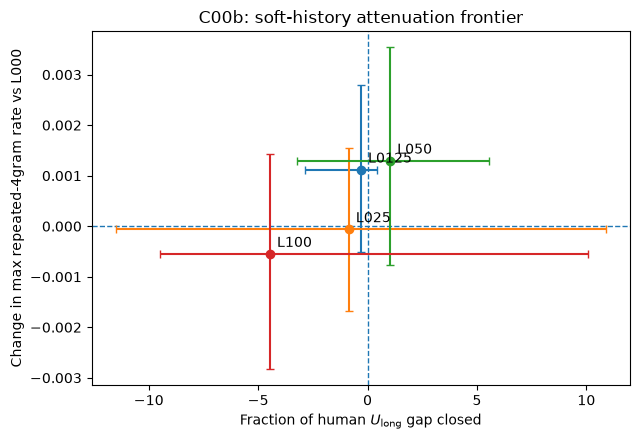

saved: ../results/causal/C00b_soft_self_history_attenuation/frontier_maxrepeat.png


In [18]:

# Figure 1: U-gap closure vs local phrase concentration

fig, ax = plt.subplots(
    figsize=(6.5, 4.5)
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1,
)

for _, r in frontier.iterrows():

    ax.errorbar(
        r["closure"],
        r["maxrep4rate_delta"],
        xerr=[[
            r["closure"]
            - r["closure_ci_low"]
        ], [
            r["closure_ci_high"]
            - r["closure"]
        ]],
        yerr=[[
            r["maxrep4rate_delta"]
            - r["maxrep4rate_ci_low"]
        ], [
            r["maxrep4rate_ci_high"]
            - r["maxrep4rate_delta"]
        ]],
        marker="o",
        capsize=3,
    )

    ax.annotate(
        r["condition"],
        (
            r["closure"],
            r["maxrep4rate_delta"],
        ),
        xytext=(5, 5),
        textcoords="offset points",
    )

ax.set_xlabel(
    r"Fraction of human $U_{\rm long}$ gap closed"
)

ax.set_ylabel(
    "Change in max repeated-4gram rate vs L000"
)

ax.set_title(
    "C00b: soft-history attenuation frontier"
)

fig.tight_layout()

path = OUT / "frontier_maxrepeat.png"
fig.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
print("saved:", path)


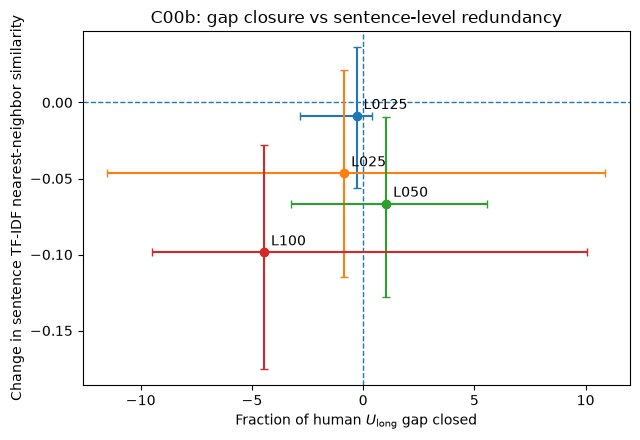

saved: ../results/causal/C00b_soft_self_history_attenuation/frontier_sentence_redundancy.png


In [19]:

# Figure 2: U-gap closure vs sentence-level redundancy proxy

fig, ax = plt.subplots(
    figsize=(6.5, 4.5)
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1,
)

for _, r in frontier.iterrows():

    ax.errorbar(
        r["closure"],
        r["sentnn_delta"],
        xerr=[[
            r["closure"]
            - r["closure_ci_low"]
        ], [
            r["closure_ci_high"]
            - r["closure"]
        ]],
        yerr=[[
            r["sentnn_delta"]
            - r["sentnn_ci_low"]
        ], [
            r["sentnn_ci_high"]
            - r["sentnn_delta"]
        ]],
        marker="o",
        capsize=3,
    )

    ax.annotate(
        r["condition"],
        (
            r["closure"],
            r["sentnn_delta"],
        ),
        xytext=(5, 5),
        textcoords="offset points",
    )

ax.set_xlabel(
    r"Fraction of human $U_{\rm long}$ gap closed"
)

ax.set_ylabel(
    "Change in sentence TF-IDF nearest-neighbor similarity"
)

ax.set_title(
    "C00b: gap closure vs sentence-level redundancy"
)

fig.tight_layout()

path = OUT / "frontier_sentence_redundancy.png"

fig.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
print("saved:", path)


=== RAW LOSS / PERPLEXITY RESPONSE ===


,condition,lambda,metric,n,L000_mean,condition_mean,delta_L,delta_L_ci_low,delta_L_ci_high,geomean_ppl_ratio,ppl_ratio_ci_low,ppl_ratio_ci_high
2,L0125,0.125,L_128,23,0.733446,0.811858,0.078411,-0.097046,0.254856,1.081568,0.907514,1.290276
3,L0125,0.125,L_256,23,0.568677,0.648853,0.080176,-0.068648,0.238596,1.083477,0.933655,1.269466
1,L0125,0.125,L_32,23,1.490427,1.648477,0.158050,-0.070119,0.391946,1.171225,0.932283,1.479857
0,L0125,0.125,L_8,23,2.554355,2.792001,0.237646,-0.067781,0.546615,1.268260,0.934465,1.727395
6,L025,0.250,L_128,18,0.681328,0.818354,0.137026,-0.064634,0.362899,1.146858,0.937410,1.437490
7,L025,0.250,L_256,18,0.559125,0.758751,0.199626,-0.048911,0.469783,1.220946,0.952266,1.599648
5,L025,0.250,L_32,18,1.268536,1.783560,0.515024,0.158186,0.872883,1.673679,1.171384,2.393803
4,L025,0.250,L_8,18,2.404472,2.855899,0.451428,0.035594,0.855038,1.570553,1.036235,2.351465
10,L050,0.500,L_128,19,0.713504,0.619322,-0.094182,-0.324141,0.142647,0.910117,0.723148,1.153322
11,L050,0.500,L_256,19,0.573869,0.537395,-0.036474,-0.255555,0.209361,0.964183,0.774487,1.232889



=== WHERE DOES THE U SHIFT COME FROM? ===


,condition,lambda,k,delta_L8,delta_Lk,implied_delta_U,direct_delta_U,identity_error
0,L0125,0.125,32,0.237646,0.158050,0.079596,0.079596,-1.387779e-17
1,L0125,0.125,128,0.237646,0.078411,0.159235,0.159235,0.000000e+00
2,L0125,0.125,256,0.237646,0.080176,0.157470,0.157470,0.000000e+00
3,L025,0.250,32,0.451428,0.515024,-0.063596,-0.063596,-1.387779e-17
4,L025,0.250,128,0.451428,0.137026,0.314402,0.314402,-5.551115e-17
5,L025,0.250,256,0.451428,0.199626,0.251802,0.251802,0.000000e+00
6,L050,0.500,32,-0.392969,-0.015176,-0.377792,-0.377792,0.000000e+00
7,L050,0.500,128,-0.392969,-0.094182,-0.298787,-0.298787,5.551115e-17
8,L050,0.500,256,-0.392969,-0.036474,-0.356495,-0.356495,0.000000e+00
9,L100,1.000,32,0.277504,0.100539,0.176965,0.176965,0.000000e+00


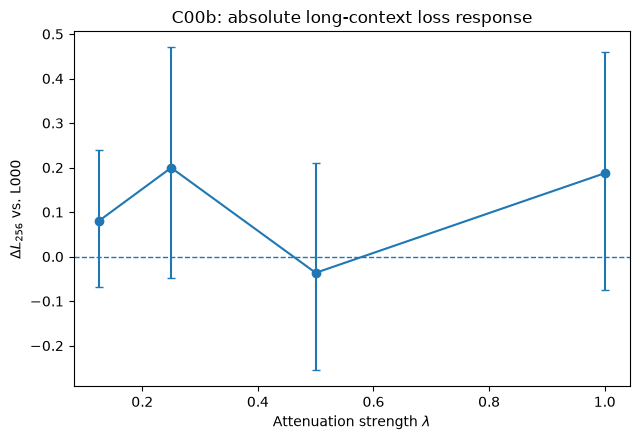

saved: ../results/causal/C00b_soft_self_history_attenuation/raw_L256_response.png


In [21]:
# ============================================================
# 8b. Raw loss / perplexity response to soft attenuation
#
# U(k) = L_8 - L_k deliberately removes the absolute loss
# level. Here we ask whether soft history attenuation also
# changes raw scorer likelihood, which is itself commonly used
# in machine-text detection.
#
# Primary quantities:
#
#   ΔL_k(lambda) = E[L_k(lambda) - L_k(L000)]
#
# and
#
#   PPL ratio = exp(ΔL_k)
#
# so:
#   ratio < 1  -> attenuated text is MORE predictable to scorer
#   ratio > 1  -> attenuated text is LESS predictable to scorer
#
# The exact same paired, baseline-defined treatment populations
# used by the U analysis are retained.
# ============================================================

L_METRICS = ["L_8", "L_32", "L_128", "L_256"]
TREATMENTS = [c for c in CONDITIONS if c != "L000"]

missing = [c for c in L_METRICS if c not in analysis.columns]
assert not missing, f"Missing raw-loss columns: {missing}"

loss_rows = []

for cond_i, condition in enumerate(TREATMENTS):

    # Same baseline-defined population logic as C00b:
    # source must be L000-eligible and remain measurable
    # under this treatment.
    treatment_ids = set(
        analysis.loc[
            analysis["condition"].eq(condition)
            & analysis["source_id"].astype(str).isin(baseline_ids)
            & analysis["eligible_U"].fillna(False),
            "source_id",
        ].astype(str)
    )

    for metric_i, metric in enumerate(L_METRICS):

        pair = (
            analysis[
                analysis["source_id"].astype(str).isin(treatment_ids)
                & analysis["condition"].isin(["L000", condition])
            ]
            .pivot(
                index="source_id",
                columns="condition",
                values=metric,
            )[[condition, "L000"]]
            .dropna()
        )

        d = (
            pair[condition] - pair["L000"]
        ).to_numpy(float)

        rr = np.random.default_rng(
            BOOT_SEED
            + 30000
            + 100 * cond_i
            + metric_i
        )

        bs = np.empty(N_BOOT)

        for b in range(N_BOOT):
            ix = rr.integers(0, len(d), len(d))
            bs[b] = d[ix].mean()

        delta = float(d.mean())
        lo = float(np.quantile(bs, 0.025))
        hi = float(np.quantile(bs, 0.975))

        # Since PPL = exp(L), exponentiating a difference in
        # mean log-loss gives the geometric-mean PPL ratio.
        loss_rows.append({
            "condition": condition,
            "lambda": LAMBDA_BY_CONDITION[condition],
            "metric": metric,
            "n": len(d),

            "L000_mean": float(pair["L000"].mean()),
            "condition_mean": float(pair[condition].mean()),

            "delta_L": delta,
            "delta_L_ci_low": lo,
            "delta_L_ci_high": hi,

            "geomean_ppl_ratio": float(np.exp(delta)),
            "ppl_ratio_ci_low": float(np.exp(lo)),
            "ppl_ratio_ci_high": float(np.exp(hi)),
        })


loss_response = pd.DataFrame(loss_rows)

print("=== RAW LOSS / PERPLEXITY RESPONSE ===")

display(
    loss_response[
        [
            "condition",
            "lambda",
            "metric",
            "n",
            "L000_mean",
            "condition_mean",
            "delta_L",
            "delta_L_ci_low",
            "delta_L_ci_high",
            "geomean_ppl_ratio",
            "ppl_ratio_ci_low",
            "ppl_ratio_ci_high",
        ]
    ].sort_values(
        ["lambda", "metric"]
    )
)

loss_response.to_csv(
    OUT / "raw_loss_response.csv",
    index=False,
)


# ------------------------------------------------------------
# Critical decomposition:
#
#     ΔU(k) = ΔL_8 - ΔL_k
#
# This tells us WHY U moved.
# ------------------------------------------------------------

decomp_rows = []

for condition in TREATMENTS:

    sub = (
        loss_response[
            loss_response["condition"].eq(condition)
        ]
        .set_index("metric")
    )

    for k in [32, 128, 256]:

        implied_delta_U = (
            sub.loc["L_8", "delta_L"]
            - sub.loc[f"L_{k}", "delta_L"]
        )

        # Direct paired U shift on the exact same treatment-
        # retained population.
        treatment_ids = set(
            analysis.loc[
                analysis["condition"].eq(condition)
                & analysis["source_id"].astype(str).isin(baseline_ids)
                & analysis["eligible_U"].fillna(False),
                "source_id",
            ].astype(str)
        )

        uw = (
            analysis[
                analysis["source_id"].astype(str).isin(treatment_ids)
                & analysis["condition"].isin(["L000", condition])
            ]
            .pivot(
                index="source_id",
                columns="condition",
                values=f"U_{k}",
            )[[condition, "L000"]]
            .dropna()
        )

        direct_delta_U = float(
            (uw[condition] - uw["L000"]).mean()
        )

        decomp_rows.append({
            "condition": condition,
            "lambda": LAMBDA_BY_CONDITION[condition],
            "k": k,

            "delta_L8":
                sub.loc["L_8", "delta_L"],

            "delta_Lk":
                sub.loc[f"L_{k}", "delta_L"],

            "implied_delta_U":
                implied_delta_U,

            "direct_delta_U":
                direct_delta_U,

            "identity_error":
                implied_delta_U - direct_delta_U,
        })


loss_u_decomposition = pd.DataFrame(decomp_rows)

print("\n=== WHERE DOES THE U SHIFT COME FROM? ===")

display(
    loss_u_decomposition[
        [
            "condition",
            "lambda",
            "k",
            "delta_L8",
            "delta_Lk",
            "implied_delta_U",
            "direct_delta_U",
            "identity_error",
        ]
    ]
)

assert np.allclose(
    loss_u_decomposition["identity_error"],
    0.0,
    atol=1e-10,
), "U = L8 - Lk decomposition failed."

loss_u_decomposition.to_csv(
    OUT / "raw_loss_U_decomposition.csv",
    index=False,
)


# ------------------------------------------------------------
# Detector-oriented visualization.
#
# L256 is the longest-context absolute loss available here and
# is the most natural raw-perplexity coordinate to highlight.
# ------------------------------------------------------------

plot_df = (
    loss_response[
        loss_response["metric"].eq("L_256")
    ]
    .sort_values("lambda")
)

fig, ax = plt.subplots(figsize=(6.5, 4.5))

ax.axhline(0, linestyle="--", linewidth=1)

ax.errorbar(
    plot_df["lambda"],
    plot_df["delta_L"],

    yerr=[
        plot_df["delta_L"]
        - plot_df["delta_L_ci_low"],

        plot_df["delta_L_ci_high"]
        - plot_df["delta_L"],
    ],

    marker="o",
    capsize=3,
)

ax.set_xlabel(r"Attenuation strength $\lambda$")
ax.set_ylabel(r"$\Delta L_{256}$ vs. L000")
ax.set_title(
    "C00b: absolute long-context loss response"
)

fig.tight_layout()

LOSS_FIG = OUT / "raw_L256_response.png"

fig.savefig(
    LOSS_FIG,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("saved:", LOSS_FIG)


## 12. Manual prose inspection

Statistics are not sufficient to determine whether attenuation preserves the
central idea and structure.

After the quantitative frontier is visible, choose a promising attenuation strength
and inspect actual matched prose.

The helper below displays `L000` and any requested attenuated condition side by
side together with the original prompt.


In [20]:

from IPython.display import HTML, display
import html


def show_pair(source_id, condition="L050"):

    assert condition in CONDITIONS[1:]

    p = prompts[
        prompts["source_id"].astype(str).eq(
            str(source_id)
        )
    ].iloc[0]

    b = generations[
        generations["source_id"].astype(str).eq(
            str(source_id)
        )
        & generations["condition"].eq(
            "L000"
        )
    ].iloc[0]

    t = generations[
        generations["source_id"].astype(str).eq(
            str(source_id)
        )
        & generations["condition"].eq(
            condition
        )
    ].iloc[0]

    display(
        HTML(
            f"""
            <div style="border:1px solid #aaa;padding:14px;border-radius:8px;">
              <div style="background:#f5f5f5;padding:10px;margin-bottom:12px;white-space:pre-wrap;">
                <b>PROMPT</b><br>{html.escape(str(p['prompt']))}
              </div>

              <div style="display:grid;grid-template-columns:1fr 1fr;gap:16px;">
                <div>
                  <h4>L000 — unattenuated</h4>
                  <div style="white-space:pre-wrap;border:1px solid #ddd;padding:12px;">
                    {html.escape(str(b['generated_text']))}
                  </div>
                </div>

                <div>
                  <h4>{html.escape(condition)}</h4>
                  <div style="white-space:pre-wrap;border:1px solid #ddd;padding:12px;">
                    {html.escape(str(t['generated_text']))}
                  </div>
                </div>
              </div>
            </div>
            """
        )
    )


# Convenience: inspect the first baseline-defined source.
if baseline_ids:
    show_pair(
        sorted(baseline_ids)[0],
        condition="L050",
    )



# Interpretation map

## Strong result

The most interesting outcome is an attenuation strength \(\lambda^\star\) for which:

1. \(U_{\rm long}\) human-gap closure is clearly positive;
2. the three-coordinate \(U\) displacement points toward humans;
3. baseline-defined scorer retention remains high;
4. stopping behavior remains close to `L000`;
5. sentence/lexical redundancy diagnostics change much less than under hard \(K=32\);
6. manual inspection shows preservation of the document's central ideas and
   macro-structure.

Then C00 + C00b jointly support:

\[
\boxed{
\text{the human--LLM dependency gap is sensitive to the \emph{strength} of}
}
\]

\[
\boxed{
\text{long-range autoregressive self-history, not merely its hard availability.}
}
\]

That is substantially more informative than the original truncation result.

## Soft attenuation changes \(U\) but still harms content

Then long-range attention strength remains a causal source of the RELIC trace, but
the human-directed displacement may still be inseparable from a quality/content
tradeoff at this model scale.

## Soft attenuation preserves prose but does not close the gap

Then the hard-C00 effect depended on aggressive removal rather than a smooth
reduction in old-history influence. That would sharply limit the mechanistic claim.

## No trace movement

Then hard truncation established sensitivity to **availability**, but not evidence
that ordinary variation in long-range attention strength explains the human--LLM
difference.

---

## What comes next

Do not design a post-generation "humanization" transform until the actual C00b
samples have been read.

If a soft operating point moves multiple empirical traces toward humans while
preserving ideas and structure, the natural next experiment is to ask whether the
same output signature can be reproduced **post generation** subject to explicit
semantic/content-invariance constraints.
